# 频率轴、幅相谱与逆变换

用已知频率和幅度的合成信号检查双边谱、单边谱、相位约定和多通道 FFT。

## FFT 的下标、正频率与负频率

In [1]:
import numpy as np

# 为教学例子指定采样率：每秒采样 8 次
fs = 8.0

# 四点测试信号
x = np.array(
    [3 + 3j, -2 + 2j, -1 - 3j, 4 - 2j],
    dtype=complex
)

# 采样点数
N = len(x)

# 相邻采样点之间的时间，单位是秒
sample_interval = 1 / fs

# 计算 FFT
X = np.fft.fft(x)

# 为每个 FFT 输出位置生成对应的频率标签
frequencies = np.fft.fftfreq(N, d=sample_interval)

print("采样间隔（秒）：", sample_interval)
print("频率轴（Hz）：", frequencies)
print("FFT 输出：", np.round(X, 3))

采样间隔（秒）： 0.125
频率轴（Hz）： [ 0.  2. -4. -2.]
FFT 输出： [4. +0.j 8.+12.j 0. +0.j 0. +0.j]


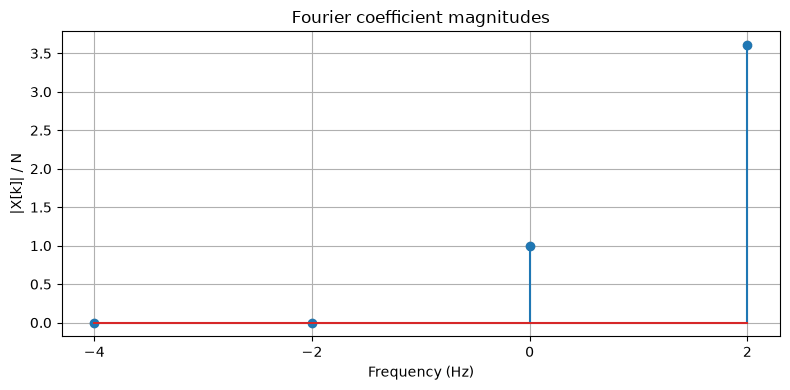

In [2]:
import matplotlib.pyplot as plt

# 换算成直接用于重建的复数系数
coefficients = X / N

# 取每个复数系数的模长，作为图上的高度
magnitudes = np.abs(coefficients)

# 创建图和绘图区
fig, ax = plt.subplots(figsize=(8, 4))

# 横坐标是频率，纵坐标是对应系数的模长
ax.stem(frequencies, magnitudes)

# 在四个实际频率位置上显示刻度
ax.set_xticks(frequencies)

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("|X[k]| / N")
ax.set_title("Fourier coefficient magnitudes")
ax.grid(True)

plt.tight_layout()
plt.show()

## 从双边谱读余弦的幅度

In [3]:
import numpy as np

# 1. 设置采样条件和信号参数
fs = 8.0
N = 4

A = 2.0
f0 = 2.0

# 2. 生成采样编号和对应的时间
n = np.arange(N)
t = n / fs

# 3. 生成实数余弦信号
x = A * np.cos(2 * np.pi * f0 * t)

# 4. 计算 DFT，并生成每个位置对应的频率
X = np.fft.fft(x)
frequencies = np.fft.fftfreq(N, d=1 / fs)

# 5. 将 DFT 输出换算为复指数基向量的系数
coefficients = X / N

# 6. 本例中，下标 1 对应正频率 2 Hz
recovered_amplitude = 2 * np.abs(X[1]) / N

print("采样时间：", t)
print("采样值：", np.round(x, 3))
print("频率轴（Hz）：", frequencies)
print("DFT 输出：", np.round(X, 3))
print("复指数系数：", np.round(coefficients, 3))
print("恢复的余弦幅度：", recovered_amplitude)

采样时间： [0.    0.125 0.25  0.375]
采样值： [ 2.  0. -2. -0.]
频率轴（Hz）： [ 0.  2. -4. -2.]
DFT 输出： [-0.+0.j  4.-0.j  0.+0.j  4.+0.j]
复指数系数： [-0.+0.j  1.-0.j  0.+0.j  1.+0.j]
恢复的余弦幅度： 2.0


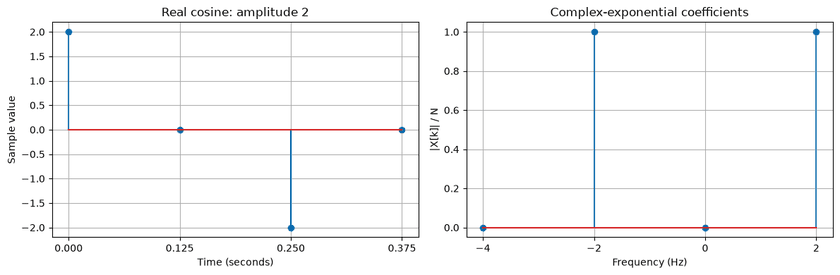

In [4]:
import matplotlib.pyplot as plt

# 创建一行两列的子图
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 左图：时域中的四个采样值
axes[0].stem(t, x)
axes[0].set_xticks(t)
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Sample value")
axes[0].set_title("Real cosine: amplitude 2")
axes[0].grid(True)

# 右图：各个复指数系数的模长
axes[1].stem(frequencies, np.abs(coefficients))
axes[1].set_xticks(frequencies)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("|X[k]| / N")
axes[1].set_title("Complex-exponential coefficients")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 单边谱的缩放和逆变换

In [5]:
import numpy as np

# 1. 设置采样条件和信号参数
fs = 8.0
N = 4

A = 2.0
f0 = 2.0

# 2. 生成采样时间和实数余弦
n = np.arange(N)
t = n / fs

x = A * np.cos(2 * np.pi * f0 * t)

# 3. 计算实数输入的 FFT
R = np.fft.rfft(x)

# 4. 生成与 R 一一对应的频率轴
frequencies = np.fft.rfftfreq(N, d=1 / fs)

# 5. 先取模长，再除以原信号的采样点数
amplitudes = np.abs(R) / N

# 6. 将普通正频率处的幅度乘以 2
if N % 2 == 0:
    # 偶数长度：排除 DC 和 Nyquist
    amplitudes[1:-1] *= 2
else:
    # 奇数长度：只排除 DC
    amplitudes[1:] *= 2

print("输入信号：", np.round(x, 3))
print("rfft 输出：", np.round(R, 3))
print("频率轴（Hz）：", frequencies)
print("单边幅度谱：", np.round(amplitudes, 3))

输入信号： [ 2.  0. -2. -0.]
rfft 输出： [-0.+0.j  4.-0.j  0.+0.j]
频率轴（Hz）： [0. 2. 4.]
单边幅度谱： [0. 2. 0.]


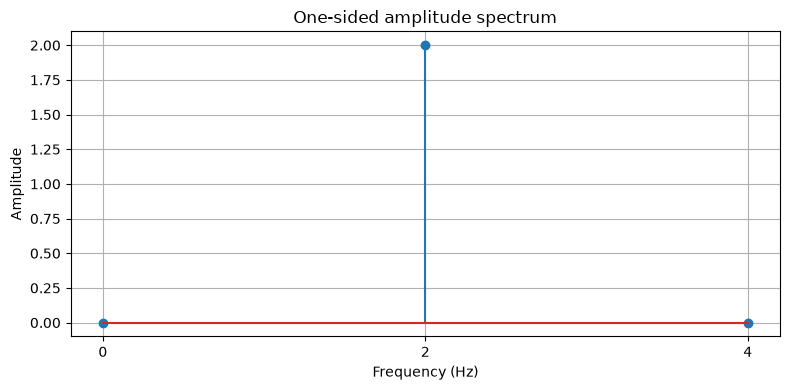

In [6]:
import matplotlib.pyplot as plt

# 创建一张画布和一块绘图区
fig, ax = plt.subplots(figsize=(8, 4))

# 横坐标是频率，纵坐标是换算后的幅度
ax.stem(frequencies, amplitudes)

# 显示每一个频率位置的刻度
ax.set_xticks(frequencies)

# 设置坐标轴说明和标题
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Amplitude")
ax.set_title("One-sided amplitude spectrum")

# 显示网格，调整布局，显示图像
ax.grid(True)
plt.tight_layout()
plt.show()

In [7]:
x_reconstructed = np.fft.irfft(R, n=N)

print("重建信号：", np.round(x_reconstructed, 3))
print("是否恢复成功：", np.allclose(x_reconstructed, x))

重建信号： [ 2.  0. -2. -0.]
是否恢复成功： True


## 两路波形相加后的幅频谱

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# 每秒采样 128 次，记录 2 秒
fs = 128
duration = 2.0

N = int(fs * duration)       # 256 个采样点
t = np.arange(N) / fs        # 每个点对应的时间，单位为秒

# 两个不同频率的成分，约定单位为微伏
x10 = 20 * np.sin(2 * np.pi * 10 * t)

x22 = 8 * np.sin(
    2 * np.pi * 22 * t + np.pi / 4
)

# 在每一个采样时刻，把两条波的数值相加
x = x10 + x22

print(x.shape)

(256,)


In [9]:
# 对实数信号计算 FFT，保留非负频率部分
X = np.fft.rfft(x)

# 为每个频点生成对应的实际频率，单位为 Hz
freqs = np.fft.rfftfreq(N, d=1 / fs)

print("原始信号形状：", x.shape)
print("FFT 结果形状：", X.shape)
print("频率轴形状：", freqs.shape)

print("前几个频率：", freqs[:6])
print("最后一个频率：", freqs[-1])

原始信号形状： (256,)
FFT 结果形状： (129,)
频率轴形状： (129,)
前几个频率： [0.  0.5 1.  1.5 2.  2.5]
最后一个频率： 64.0


In [10]:
# 先取复数的模，再除以原始采样点数
amplitude = np.abs(X) / N

# 换算成单边幅度谱
if N % 2 == 0:
    # 偶数长度：直流和奈奎斯特频点不翻倍
    amplitude[1:-1] *= 2
else:
    # 奇数长度：只有直流不翻倍
    amplitude[1:] *= 2

print("10 Hz 的幅度：", amplitude[20])
print("22 Hz 的幅度：", amplitude[44])

10 Hz 的幅度： 20.0
22 Hz 的幅度： 8.0


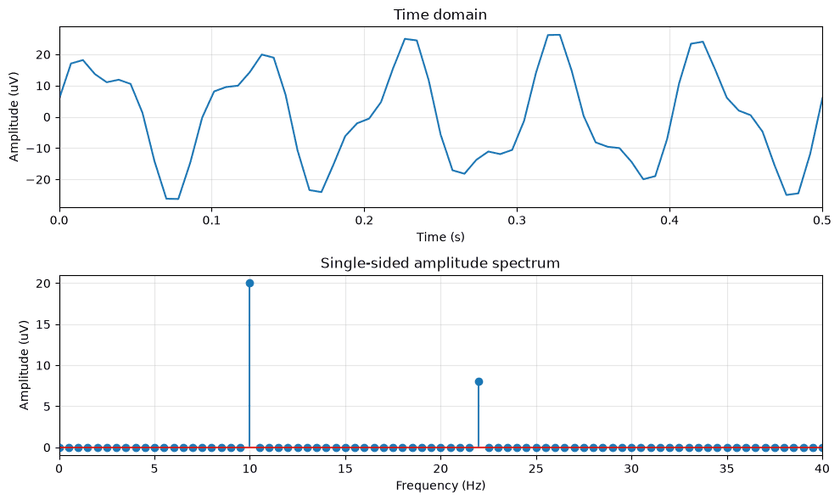

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# 第一张图：信号随时间如何变化
axes[0].plot(t, x)
axes[0].set_xlim(0, 0.5)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude (uV)")
axes[0].set_title("Time domain")
axes[0].grid(alpha=0.3)

# 第二张图：各个频点的幅度
axes[1].stem(freqs, amplitude)
axes[1].set_xlim(0, 40)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Amplitude (uV)")
axes[1].set_title("Single-sided amplitude spectrum")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
phase10 = np.angle(X[20])
phase22 = np.angle(X[44])

print("10 Hz 的相位：", phase10)
print("22 Hz 的相位：", phase22)

# 使用完整复数频谱进行逆变换
x_reconstructed = np.fft.irfft(X, n=N)

print("能否还原：", np.allclose(x, x_reconstructed))

print(
    "最大误差：",
    np.max(np.abs(x - x_reconstructed))
)

10 Hz 的相位： -1.5707963267948992
22 Hz 的相位： -0.785398163397468
能否还原： True
最大误差： 1.4210854715202004e-14


## 沿多通道张量的采样轴变换

In [13]:
# 仅用于演示形状：2 个样本、4 个通道、每通道 N 个点
eeg = np.zeros((2, 4, N))

# 把双频混合信号放进第 0 个样本的第 0 个通道
eeg[0, 0, :] = x

S = eeg.shape[-1]

# 对每个样本、每个通道分别进行 FFT
X_eeg = np.fft.rfft(eeg, axis=-1)

print("输入形状：", eeg.shape)
print("输出形状：", X_eeg.shape)

amplitude_eeg = np.abs(X_eeg) / S

if S % 2 == 0:
    amplitude_eeg[..., 1:-1] *= 2
else:
    amplitude_eeg[..., 1:] *= 2

输入形状： (2, 4, 256)
输出形状： (2, 4, 129)


## 复系数的模与相位，按原相位重建正弦

In [14]:
import numpy as np

z = 1 - 1j

print("复数的模：", np.abs(z))
print("角度，弧度制：", np.angle(z))
print("角度，角度制：", np.angle(z, deg=True))

复数的模： 1.4142135623730951
角度，弧度制： -0.7853981633974483
角度，角度制： -45.0


In [15]:
import numpy as np

# 采样设置：128 Hz，记录 256 个点，也就是 2 秒
fs = 128
N = 256
t = np.arange(N) / fs

# 我们事先设置的正弦初始相位
phase_sin = np.pi / 4

# 生成幅度为 20、频率为 10 Hz 的信号
x = 20 * np.sin(
    2 * np.pi * 10 * t + phase_sin
)

# 计算 FFT
X = np.fft.rfft(x)

# 频点间隔为 128/256 = 0.5 Hz
# 因此，第 20 个频点对应 10 Hz
k = 20
z = X[k]

# FFT 系数的角度，对应余弦写法中的相位
phase_cos = np.angle(z)

# 转换回正弦写法中的相位
phase_sin_recovered = phase_cos + np.pi / 2

print("生成时的正弦相位：", phase_sin)
print("FFT 读出的余弦相位：", phase_cos)
print("换回正弦相位：", phase_sin_recovered)

生成时的正弦相位： 0.7853981633974483
FFT 读出的余弦相位： -0.7853981633974527
换回正弦相位： 0.7853981633974438


In [16]:
# 从 FFT 系数读出幅度
amplitude = 2 * np.abs(z) / N

# 使用余弦形式，以及 FFT 直接读出的相位
x_reconstructed = amplitude * np.cos(
    2 * np.pi * 10 * t + phase_cos
)

# 比较全部采样点，允许微小的浮点误差
print(np.allclose(x, x_reconstructed))

True
